# Demo: simulated PTP - buszaki

This notebook simulates a dataset

In [18]:
# ==============================
# Demo parameters (customize)
# ==============================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, hilbert, sawtooth
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from scipy.stats import circmean

In [19]:

# -----------------------------
# Configuration (edit here)
# -----------------------------
SEED = 7
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# --- Timeline
fs      = 250            # Hz
T_sec   = 10            # seconds
t       = np.arange(0, T_sec, 1/fs)
N       = t.size
MODE = "biased_rw"  # "constant" | "nonstationary" | "biased_rw"

# --- Cell counts ---
n_place         = 15
n_multipeak     = 10
n_noisy         = 40
n_hd            = 5
n_cells_total   = n_place + n_multipeak + n_noisy + n_hd
ALLOW_SEGMENTS = [(-1.0, -0.55), (-0.4, 0.3), (0.45, 0.85)] # (-1,1)
# ALLOW_SEGMENTS = None

# --- LFP channel count
n_lfp = 16


# --- Global theta parameters
THETA_F0 = 8.0
THETA_WOBBLE1_HZ  = 0.02
THETA_WOBBLE2_HZ  = 0.006
THETA_WOBBLE1_AMP = 0.4
THETA_WOBBLE2_AMP = 0.2

# --- Amplitude envelope
AMP_BASE         = 0.60
AMP_SPEED_GAIN   = 0.35
AMP_DRIFT_GAIN   = 0.15
AMP_DRIFT_FREQ   = 0.015

# --- LFP phase spatial modulation
CH_PHASE_JITTER_DEG = 30.0
PHASE_WIGGLE_POS1   = 0.15
PHASE_WIGGLE_POS2   = 0.08
PHASE_POS_GAIN = 0.15
AMP_POS_GAIN = 0.0

# --- PSP (spike → LFP)
PSP_KERNEL_MS  = 40
PSP_GAIN       = 0.15

# --- Noise
NOISE_WHITE_STD = 0.30
NOISE_PINK_STD  = 0.25

# --- Place field defaults
PF_WIDTH_RANGE = (0.10, 0.22)
PF_PEAK_HZ     = (6.0, 12.0)
PF_BASE_HZ     = (0.1, 0.4)
PF_KAPPA       = (2.0, 6.0)

# --- Multi-peak defaults
MP_NUM_RANGE   = (2, 4)
MP_WIDTH_RANGE = (0.12, 0.28)
MP_AMP_RANGE   = (3.0, 7.0)
MP_KAPPA       = (1.0, 3.0)

# --- Noisy units
NOISY_KAPPA    = (0.0, 1.0)
NOISY_RW_STD   = 0.04

# --- Coverage plotting
COVERAGE_N_BINS = 50


# -----------------------------
# Helpers
# -----------------------------
def allowed_mask(pos, segments):
    if segments is None:
        return np.ones_like(pos, dtype=float)
    m = np.zeros_like(pos, dtype=float)
    for a,b in segments:
        m += ((pos>=a) & (pos<=b)).astype(float)
    return np.clip(m, 0, 1)

def sample_center_from_allowed(rng, segments):
    if segments is None:
        return rng.uniform(-0.9, 0.9)
    seg = segments[rng.integers(len(segments))]
    return rng.uniform(seg[0], seg[1])

# ============================
# Movement models (pick one)
# ============================
def _normalize_speed(v):
    v_abs = np.abs(v)
    return v_abs / (v_abs.max() + 1e-9)

# 1) Linear back-and-forth at constant speed (triangle wave on [-1,1])
def movement_constant_linear(t, fs, f_traversal=0.10):
    """
    f_traversal: traversals per second (0.10 => one full back+forth every 10 s)
    """
    # triangle wave in [-1, 1]
    x = sawtooth(2*np.pi*f_traversal*t, width=0.5)  # symmetric up/down
    v_animal = np.gradient(x) * fs                  # signed velocity
    v_norm = _normalize_speed(v_animal)
    return x.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)

# 2) Nonstationary speed (your current style: slow accel/decel over time)
def movement_nonstationary(t, fs,
                           base=0.22,
                           a1=0.07, f1=0.010, phi1=0.7,
                           a2=0.03, f2=0.045, phi2=1.1,
                           min_speed=0.05):
    """
    base + slow sinusoidal modulations (always >= min_speed)
    """
    speed_profile = (base
                     + a1*np.sin(2*np.pi*f1*t + phi1)
                     + a2*np.sin(2*np.pi*f2*t + phi2))
    speed_profile = np.clip(speed_profile, min_speed, None)

    # integrate speed to distance (phase), then wrap onto [-1,1] via sine
    phase = 2*np.pi * np.cumsum(speed_profile) / fs
    x = np.sin(phase)
    v_animal = np.gradient(x) * fs
    v_norm = _normalize_speed(v_animal)
    return x.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)


def movement_discrete(t, fs,
                                         step_size=0.006,      # per-sample displacement → faster movement
                                         decision_interval=15, # samples between decisions (~60 ms @ 250Hz)
                                         turn_prob_scale=5.5,  # steepness of turning near wall
                                         pause_prob_base=0.05, # baseline pause chance
                                         boundary=1.0):
    """
    3-action (forward / backward / pause) movement model with soft boundaries.
    Near the boundary, animal has 50% chance to pause and 50% to turn.
    Between boundaries, it tends to continue moving, sometimes pausing.
    """

    N = len(t)
    x = np.zeros(N, dtype=np.float32)
    v = np.zeros(N, dtype=np.float32)

    direction = 1.0  # initial direction (+1 forward, -1 backward, 0 pause)

    for n in range(1, N):

        # ─ Decision rule every few samples ─
        if n % decision_interval == 0:
            # distance to nearest boundary, normalized [0,1]
            d = min((boundary - x[n-1]) / boundary,
                    (boundary + x[n-1]) / boundary)

            # --- Probabilities ---
            # General: turn probability grows near wall
            p_turn = np.exp(-turn_prob_scale * d)
            p_turn = np.clip(p_turn, 0, 1)

            # Pause probability: baseline + slightly higher near wall
            p_pause = pause_prob_base + 0.1 * (1 - d)
            p_pause = np.clip(p_pause, 0, 0.3)

            # Default forward prob = remaining
            p_forward = 1.0 - (p_turn + p_pause)
            p_forward = np.clip(p_forward, 0, 1)

            # --- Special case: at the border ---
            if abs(x[n-1]) >= 0.99 * boundary:
                p_turn = 0.5
                p_pause = 0.5
                p_forward = 0.0

            # Normalize and choose
            probs = np.array([p_forward, p_turn, p_pause])
            probs /= probs.sum()
            action = np.random.choice(["forward", "turn", "pause"], p=probs)

            if action == "turn":
                direction = -direction if direction != 0 else np.random.choice([-1, 1])
            elif action == "pause":
                direction = 0.0
            else:  # forward
                if direction == 0:
                    direction = np.random.choice([-1.0, 1.0])

        # ─ Update position ─
        x[n] = x[n-1] + direction * step_size

        # Hard reflect if we go beyond limits
        if x[n] > boundary:
            x[n] = boundary
            direction = -1.0
        elif x[n] < -boundary:
            x[n] = -boundary
            direction = 1.0

        v[n] = direction * step_size * fs

    # Smooth trajectory for continuity
    x_smooth = gaussian_filter1d(x, sigma=1.0)
    v_animal = np.gradient(x_smooth) * fs
    v_norm = np.abs(v_animal) / (np.max(np.abs(v_animal)) + 1e-9)

    return x_smooth.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)

# -----------------------------
# 1) Generate latent trajectory & global theta
# -----------------------------



if MODE == "constant":
    pos_animal, v_animal, v_norm = movement_constant_linear(t, fs, f_traversal=0.10)
elif MODE == "nonstationary":
    pos_animal, v_animal, v_norm = movement_nonstationary(t, fs)  # tweak params as desired
elif MODE == "biased_rw":
    pos_animal, v_animal, v_norm = movement_discrete(t, fs)
else:
    raise ValueError("MODE must be one of: constant, nonstationary, biased_rw")

# Keep your mask code the same:
M_allow = allowed_mask(pos_animal, ALLOW_SEGMENTS)

# Short aliases used later
x = pos_animal
M_allow = allowed_mask(x, ALLOW_SEGMENTS)

# Global theta phase
f_theta = (THETA_F0
           + THETA_WOBBLE1_AMP*np.sin(2*np.pi*THETA_WOBBLE1_HZ*t)
           + THETA_WOBBLE2_AMP*np.sin(2*np.pi*THETA_WOBBLE2_HZ*t + 0.9))
phi_theta = 2*np.pi*np.cumsum(f_theta)/fs

# Nonstationary amplitude envelope
A_env = (AMP_BASE
         + AMP_SPEED_GAIN*v_norm
         + AMP_DRIFT_GAIN*np.sin(2*np.pi*AMP_DRIFT_FREQ*t + 0.3))
A_env = np.clip(A_env, 0.1, 1.5)


# -----------------------------
# 2) Generate spiking population (place, multi, noisy, HD)
# -----------------------------
rates  = np.zeros((n_cells_total, N), dtype=np.float32)
labels = []

# --- Place cells
for i in range(n_place):
    mu  = sample_center_from_allowed(rng, ALLOW_SEGMENTS)
    sig = rng.uniform(*PF_WIDTH_RANGE)
    pk  = rng.uniform(*PF_PEAK_HZ)
    b   = rng.uniform(*PF_BASE_HZ)
    kap = rng.uniform(*PF_KAPPA)
    field = np.exp(-0.5*((x - mu)/sig)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    phase_pref = (np.pi/2) - np.pi*((x - mu)/sig)
    phase_gain = np.exp(kap * np.cos(phi_theta - phase_pref))
    rates[i]   = (b + pk * field) * phase_gain
    labels.append("place")

# --- Multi-peak cells
off = n_place
for i in range(off, off + n_multipeak):
    n_bumps = rng.integers(*MP_NUM_RANGE)
    mus  = [sample_center_from_allowed(rng, ALLOW_SEGMENTS) for _ in range(n_bumps)]
    sigs = rng.uniform(*MP_WIDTH_RANGE, size=n_bumps)
    amps = rng.uniform(*MP_AMP_RANGE, size=n_bumps)
    field = np.zeros(N)
    for m,s,a in zip(mus,sigs,amps):
        field += a*np.exp(-0.5*((x - m)/s)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    kap  = rng.uniform(*MP_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (rng.uniform(0.05,0.3) + field) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("multi-peak")

# --- Noisy cells
off2 = off + n_multipeak
for i in range(off2, off2 + n_noisy):
    rw = np.cumsum(rng.normal(0, NOISY_RW_STD, size=N)).astype(np.float32)
    rw = (rw - rw.min()) / (rw.max() - rw.min() + 1e-9)
    base = rng.uniform(0.2, 1.0)
    amp  = rng.uniform(2.0, 5.0)
    kap  = rng.uniform(*NOISY_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (base + amp*rw) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("noisy")

# --- Head-direction cells
off3 = off2 + n_noisy
dir_signal = np.sign(v_animal)
dir_signal[dir_signal == 0] = 1
dir_angle = np.where(dir_signal > 0, np.pi/2, -np.pi/2)
dir_angle = dir_angle + rng.normal(0, 0.15, size=N)

for i in range(off3, off3 + n_hd):
    k_dir = rng.uniform(2.0, 6.0)
    pref  = rng.uniform(-np.pi, np.pi)
    base  = rng.uniform(0.2, 1.0)
    pk    = rng.uniform(8.0, 15.0)
    kap_theta = rng.uniform(1.0, 3.0)
    theta_pref = rng.uniform(-np.pi, np.pi)
    dir_term = np.exp(k_dir * np.cos(dir_angle - pref))
    dir_term /= dir_term.max() + 1e-9
    rates[i] = (base + pk * dir_term) * np.exp(kap_theta * np.cos(phi_theta - theta_pref))
    labels.append("hd")

labels = np.array(labels)
p_spike = rates / fs
spikes  = rng.random((n_cells_total, N)) < p_spike
rates_smooth = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1) * fs

print(f"Counts → place={n_place}, multi={n_multipeak}, noisy={n_noisy}, hd={n_hd}, total={len(labels)}")
print("spikes shape:", spikes.shape)
print("Trajectory:", x.shape, "Velocity:", v_animal.shape)


# -----------------------------
# 3) Spatial coverage heatmap
# -----------------------------
n_bins = COVERAGE_N_BINS
edges  = np.linspace(-1, 1, n_bins+1)
cent   = 0.5*(edges[1:] + edges[:-1])
pos_bins_all = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
occ_counts = np.bincount(pos_bins_all, minlength=n_bins)
occ_time   = occ_counts / fs + 1e-9
coverage = np.zeros((n_cells_total, n_bins), dtype=float)
for i in range(n_cells_total):
    pos_bins = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
    counts = np.bincount(pos_bins[spikes[i]], minlength=n_bins)
    coverage[i] = counts / occ_time
peak_pos = cent[np.argmax(coverage, axis=1)]
order = np.argsort(peak_pos)


# -----------------------------
# 4) Generate synthetic LFP (theta + PSP + noise)
# -----------------------------
phase_jitter = np.deg2rad(CH_PHASE_JITTER_DEG)
ch_phase = rng.uniform(-phase_jitter, phase_jitter, size=n_lfp)
x_norm = (x - x.min()) / (x.max() - x.min() + 1e-9)
phase_pos_jitter = np.zeros((N, n_lfp), dtype=np.float32)
for ch in range(n_lfp):
    a1, b1 = rng.normal(0,1), rng.normal(0,1)
    a2, b2 = rng.normal(0,1), rng.normal(0,1)
    phase_pos_jitter[:, ch] = PHASE_POS_GAIN * (
        0.6*np.sin(2*np.pi*x_norm)*a1 +
        0.4*np.cos(4*np.pi*x_norm)*b1 +
        0.3*np.sin(6*np.pi*x_norm)*a2 +
        0.2*np.cos(8*np.pi*x_norm)*b2
    )
amp_pos_jitter = np.zeros((N, n_lfp), dtype=np.float32)
if AMP_POS_GAIN != 0.0:
    for ch in range(n_lfp):
        c1, d1 = rng.normal(0,1), rng.normal(0,1)
        amp_pos_jitter[:, ch] = AMP_POS_GAIN * (
            0.5*np.sin(2*np.pi*x_norm)*c1 + 0.5*np.cos(2*np.pi*x_norm)*d1
        )
wiggle = (PHASE_WIGGLE_POS1*np.sin(2*np.pi*x)[:,None]
          + PHASE_WIGGLE_POS2*np.cos(4*np.pi*x)[:,None])
lfp_theta = (A_env[:,None] * (1.0 + amp_pos_jitter)) * \
            np.sin(phi_theta[:,None] + ch_phase[None,:] + phase_pos_jitter + wiggle)

kern_len = max(3, int(PSP_KERNEL_MS * fs / 1000) | 1)
win = np.hanning(kern_len); win /= (win.sum() + 1e-9)
psp = np.zeros((N, n_lfp), dtype=np.float32)
assign = rng.integers(0, n_lfp, size=n_cells_total)
for i in range(n_cells_total):
    s = spikes[i].astype(float)
    conv = np.convolve(s, win, mode='same').astype(np.float32)
    psp[:, assign[i]] += PSP_GAIN * conv

white = rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)).astype(np.float32)
pink  = np.cumsum(rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)).astype(np.float32), axis=0)
pink  = (pink - pink.mean(0)) / (pink.std(0)+1e-9) * NOISE_PINK_STD
lfp_raw = (lfp_theta + psp + white + pink).astype(np.float32)
print(f"LFP synthesized with PHASE_POS_GAIN={PHASE_POS_GAIN:.2f} (AMP_POS_GAIN={AMP_POS_GAIN:.2f})")


# -----------------------------
# 5) Theta-band filter & Hilbert
# -----------------------------
def butter_band(data, lo, hi, fs, order=3):
    b, a = butter(order, [lo, hi], btype="bandpass", fs=fs)
    return filtfilt(b, a, data)

lfp_theta_band    = np.zeros_like(lfp_raw)
lfp_phase_inst    = np.zeros_like(lfp_raw)
lfp_envelope_inst = np.zeros_like(lfp_raw)
for ch in range(n_lfp):
    lfp_theta_band[:, ch] = butter_band(lfp_raw[:, ch], 6, 10, fs)
    analytic = hilbert(lfp_theta_band[:, ch])
    lfp_envelope_inst[:, ch] = np.abs(analytic)
    lfp_phase_inst[:, ch]    = np.mod(np.angle(analytic), 2*np.pi)


Counts → place=15, multi=10, noisy=40, hd=5, total=70
spikes shape: (70, 2500)
Trajectory: (2500,) Velocity: (2500,)
LFP synthesized with PHASE_POS_GAIN=0.15 (AMP_POS_GAIN=0.00)


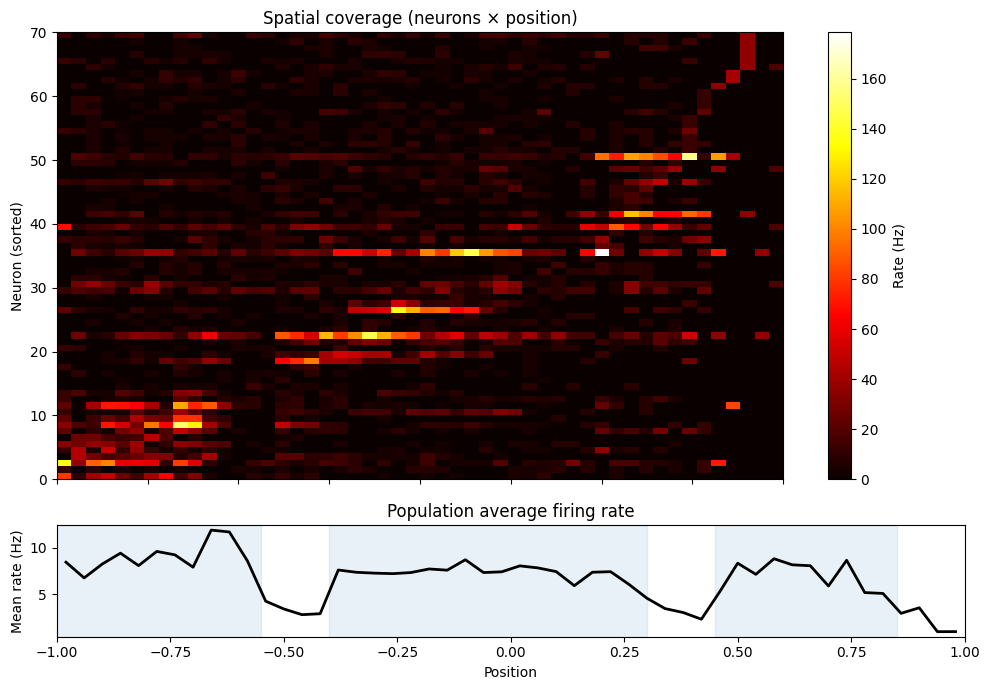

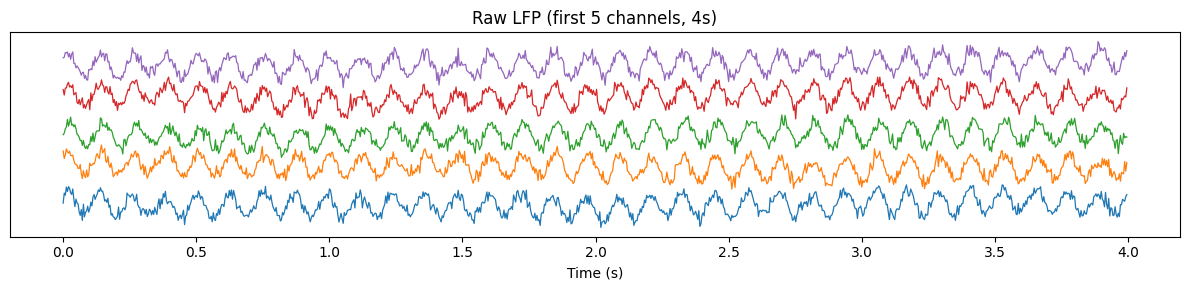

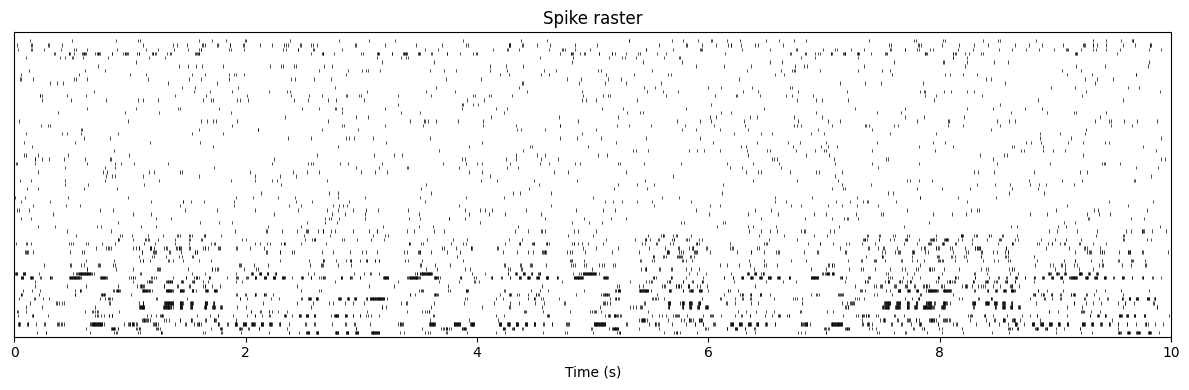

Example place cell index: 0


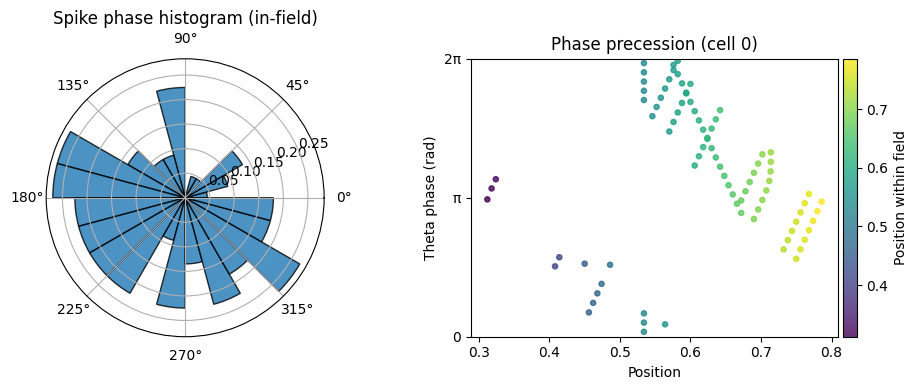

Circular mean phase (in-field): 4.11 rad, n_spikes=85
Example head-direction cell index: 65


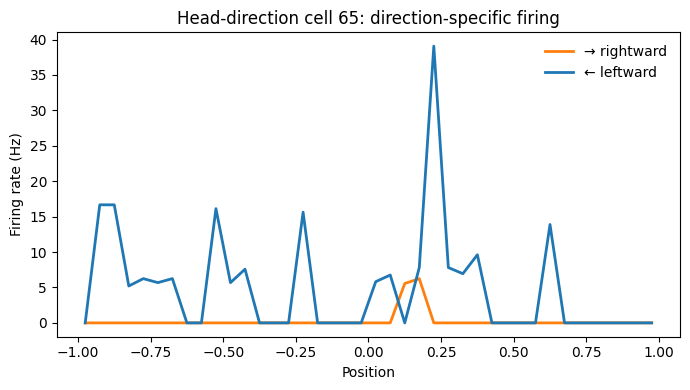

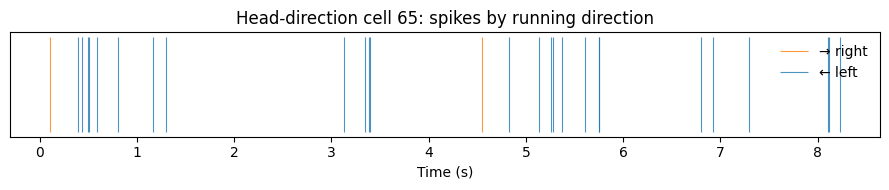

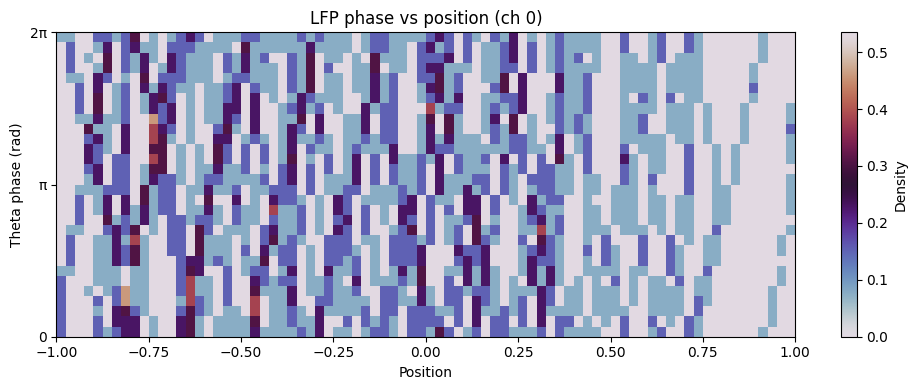

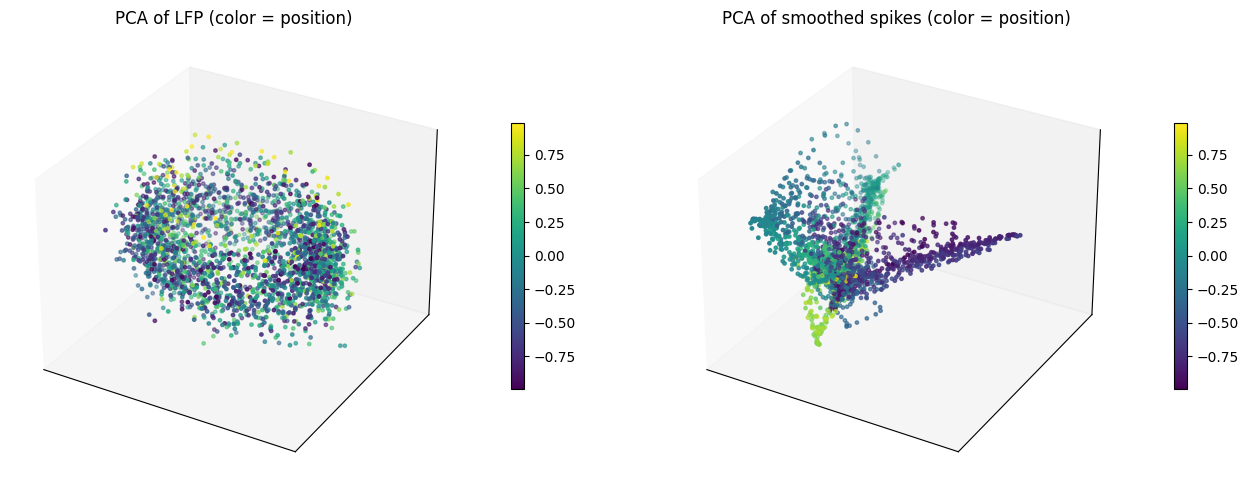

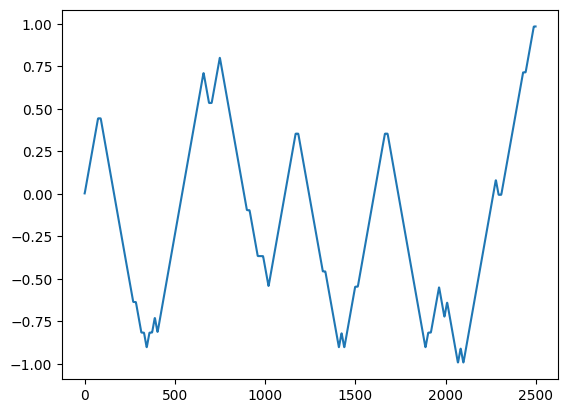

In [20]:
# ============================================================
# 6) VISUALIZATIONS  (sanity-checked, all aligned)
# ============================================================
# -----------------------------
# Population coverage heatmap + mean firing rate
# -----------------------------
mean_rate = coverage.mean(axis=0)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                       gridspec_kw={'height_ratios':[4,1]})

im = ax[0].imshow(coverage[order], aspect='auto', origin='lower',
                  extent=[-1,1,0,n_cells_total],
                  interpolation='nearest', cmap='hot')
ax[0].set_title("Spatial coverage (neurons × position)")
ax[0].set_ylabel("Neuron (sorted)")
plt.colorbar(im, ax=ax[0], label="Rate (Hz)")

ax[1].plot(cent, mean_rate, color='black', lw=2)
ax[1].set_xlabel("Position")
ax[1].set_ylabel("Mean rate (Hz)")
ax[1].set_title("Population average firing rate")

if ALLOW_SEGMENTS is not None:
    for seg in ALLOW_SEGMENTS:
        ax[1].axvspan(seg[0], seg[1], color='tab:blue', alpha=0.1)
plt.tight_layout(); plt.show()

# -----------------------------
# LFP strip plot (first few channels)
# -----------------------------
sec = 4
t_idx = slice(0, sec*fs)
n_show = min(5, n_lfp)
fig, ax = plt.subplots(figsize=(12,3))
offset = 3.0
for k in range(n_show):
    ax.plot(t[t_idx], lfp_raw[t_idx, k] + k*offset, lw=0.9)
ax.set_title(f"Raw LFP (first {n_show} channels, {sec}s)")
ax.set_xlabel("Time (s)")
ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Spike raster
# -----------------------------
fig, ax = plt.subplots(figsize=(12,4))
spike_times = [np.where(spikes[i])[0]/fs for i in range(n_cells_total)]
ax.eventplot(spike_times, colors='k', lineoffsets=np.arange(n_cells_total),
             linelengths=0.8, lw=0.5)
ax.set_xlim(0, T_sec); ax.set_ylim(-1, n_cells_total+1)
ax.set_title("Spike raster")
ax.set_xlabel("Time (s)"); ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Example place cell: phase precession
# -----------------------------
place_idx = np.where(labels == "place")[0]
if place_idx.size:
    i_example = int(place_idx[0])
    print(f"Example place cell index: {i_example}")

    n_bins = 50
    edges = np.linspace(-1, 1, n_bins + 1)
    pos_bins = np.digitize(x, edges) - 1
    spike_counts = np.bincount(pos_bins[spikes[i_example]], minlength=n_bins)
    occ_counts   = np.bincount(pos_bins, minlength=n_bins)
    rate_per_pos = spike_counts / (occ_counts + 1e-9)
    mu_est = edges[np.argmax(rate_per_pos)]
    sig_est = 0.15
    field_mask = (x > mu_est - 0.25) & (x < mu_est + 0.25)
    idx_sp = np.where(spikes[i_example] & field_mask)[0]
    if len(idx_sp) > 0:
        pos_in_field   = x[idx_sp]
        phase_in_field = phi_theta[idx_sp] % (2 * np.pi)

        fig = plt.figure(figsize=(10, 4))
        # Polar histogram
        ax1 = fig.add_subplot(1, 2, 1, projection='polar')
        n_bins_phase = 24
        bin_edges = np.linspace(0, 2*np.pi, n_bins_phase + 1)
        counts, _ = np.histogram(phase_in_field, bins=bin_edges, density=True)
        theta = 0.5 * (bin_edges[:-1] + bin_edges[1:])
        ax1.bar(theta, counts, width=(2*np.pi/n_bins_phase),
                align='center', alpha=0.8, edgecolor='k')
        ax1.set_title("Spike phase histogram (in-field)")

        # Phase precession scatter
        ax2 = fig.add_subplot(1, 2, 2)
        sc = ax2.scatter(pos_in_field, phase_in_field, s=14, alpha=0.8,
                         c=pos_in_field, cmap='viridis')
        ax2.set_ylim(0, 2*np.pi)
        ax2.set_yticks([0, np.pi, 2*np.pi])
        ax2.set_yticklabels(["0", "π", "2π"])
        ax2.set_xlabel("Position"); ax2.set_ylabel("Theta phase (rad)")
        ax2.set_title(f"Phase precession (cell {i_example})")
        plt.colorbar(sc, ax=ax2, label="Position within field", pad=0.01)
        plt.tight_layout(); plt.show()
        mean_phase = circmean(phase_in_field, high=2*np.pi, low=0)
        print(f"Circular mean phase (in-field): {mean_phase:.2f} rad, n_spikes={len(idx_sp)}")

# -----------------------------
# Example head-direction cell visualization
# -----------------------------
hd_idx = np.where(labels == "hd")[0]
if hd_idx.size:
    i_hd = int(hd_idx[0])
    print(f"Example head-direction cell index: {i_hd}")

    dir_signal = np.sign(v_animal)
    dir_signal[dir_signal == 0] = 1
    n_bins_dir = 40
    edges_dir  = np.linspace(-1, 1, n_bins_dir + 1)
    centers_dir = 0.5 * (edges_dir[:-1] + edges_dir[1:])
    rates_right = np.zeros(n_bins_dir)
    rates_left  = np.zeros(n_bins_dir)
    occ_right   = np.zeros(n_bins_dir)
    occ_left    = np.zeros(n_bins_dir)
    pos_bins = np.clip(np.digitize(x, edges_dir) - 1, 0, n_bins_dir - 1)

    
    for j in range(N):
        if dir_signal[j] > 0: occ_right[pos_bins[j]] += 1
        else:                 occ_left[pos_bins[j]]  += 1
    spike_idx = np.where(spikes[i_hd])[0]
    for j in spike_idx:
        if dir_signal[j] > 0: rates_right[pos_bins[j]] += 1
        else:                 rates_left[pos_bins[j]]  += 1
    rates_right = rates_right / (occ_right / fs + 1e-9)
    rates_left  = rates_left  / (occ_left  / fs + 1e-9)

    # rate vs. position
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(centers_dir, rates_right, color="tab:orange", lw=2, label="→ rightward")
    ax.plot(centers_dir, rates_left,  color="tab:blue", lw=2, label="← leftward")
    ax.set_xlabel("Position"); ax.set_ylabel("Firing rate (Hz)")
    ax.set_title(f"Head-direction cell {i_hd}: direction-specific firing")
    ax.legend(frameon=False); plt.tight_layout(); plt.show()

    # raster by direction
    fig, ax = plt.subplots(figsize=(9, 2))
    right_times = np.where(spikes[i_hd] & (dir_signal > 0))[0] / fs
    left_times  = np.where(spikes[i_hd] & (dir_signal < 0))[0] / fs
    ax.vlines(right_times, 0, 1, color="tab:orange", alpha=0.8, lw=0.8, label="→ right")
    ax.vlines(left_times,  0, 1, color="tab:blue",   alpha=0.8, lw=0.8, label="← left")
    ax.set_xlabel("Time (s)"); ax.set_yticks([])
    ax.set_title(f"Head-direction cell {i_hd}: spikes by running direction")
    ax.legend(frameon=False); plt.tight_layout(); plt.show()

# -----------------------------
# LFP phase vs position (sanity alignment)
# -----------------------------
ch = 0  # example channel
plt.figure(figsize=(10,4))
plt.hist2d(x, lfp_phase_inst[:, ch], bins=(80, 30),
           range=[[-1,1],[0,2*np.pi]], cmap='twilight', density=True)
plt.xlabel("Position"); plt.ylabel("Theta phase (rad)")
plt.title(f"LFP phase vs position (ch {ch})")
plt.colorbar(label='Density')
plt.yticks([0, np.pi, 2*np.pi], ['0', 'π', '2π'])
plt.tight_layout(); plt.show()

# -----------------------------
# PCA snapshots (color by position)
# -----------------------------
A_spike = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1).T
B_lfp   = lfp_raw.astype(np.float32)
Z_lfp  = PCA(n_components=3).fit_transform(B_lfp)
Z_rate = PCA(n_components=3).fit_transform(A_spike)
color  = x

fig = plt.figure(figsize=(14,5))
ax = fig.add_subplot(1,2,1, projection='3d')
p = ax.scatter(Z_lfp[:,0], Z_lfp[:,1], Z_lfp[:,2], c=color, s=6, cmap='viridis')
ax.set_title("PCA of LFP (color = position)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.02, pad=0.08)

ax = fig.add_subplot(1,2,2, projection='3d')
p = ax.scatter(Z_rate[:,0], Z_rate[:,1], Z_rate[:,2], c=color, s=6, cmap='viridis')
ax.set_title("PCA of smoothed spikes (color = position)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.02, pad=0.08)
plt.tight_layout(); plt.show()


plt.plot(pos_animal)


In [21]:
# -----------------------------
# 7) Final dataset dict & save
# -----------------------------
dataset = dict(
    # Spiking
    spikes_binary       = spikes.T.astype(bool),            # (n_cells, T)
    firing_rate         = rates.T.astype(np.float32),       # (n_cells, T)
    # LFP
    lfp_raw             = lfp_raw.astype(np.float32),     # (T, n_lfp)
    lfp_theta_band      = lfp_theta_band.astype(np.float32),  # (T, n_lfp)
    lfp_theta_phase     = lfp_phase_inst.astype(np.float32),  # (T, n_lfp) in [0, 2π)
    # Latents / metadata
    position            = x.astype(np.float32),           # (T,)
    head_dir            = dir_signal.astype(np.int32),
    phi_theta           = phi_theta.astype(np.float32),   # (T,)
    cell_labels         = labels,                         # (n_cells,)
    cell_to_channel_map = assign.astype(int),             # (n_cells,)
    fs                  = fs,
    # For completeness (optional to keep)
    lfp_envelope_inst   = lfp_envelope_inst.astype(np.float32),
)

print("\nDataset contents:")
for k,v in dataset.items():
    try:
        print(f"  {k:20s} -> {np.shape(v)}")
    except Exception:
        print(f"  {k:20s} -> {type(v)}")


Dataset contents:
  spikes_binary        -> (2500, 70)
  firing_rate          -> (2500, 70)
  lfp_raw              -> (2500, 16)
  lfp_theta_band       -> (2500, 16)
  lfp_theta_phase      -> (2500, 16)
  position             -> (2500,)
  head_dir             -> (2500,)
  phi_theta            -> (2500,)
  cell_labels          -> (70,)
  cell_to_channel_map  -> (70,)
  fs                   -> ()
  lfp_envelope_inst    -> (2500, 16)


In [22]:

# For convenience, also expose top-level aliases
A = dataset["firing_rate"]
B    = dataset["lfp_raw"]
# B    = dataset["lfp_phase_inst"]
position = dataset["position"]
head_dir = dataset["head_dir"]



In [23]:
from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import Conv1DEncoder, Conv1DEncoderConfig, SkippedConvEncoder, SkippedConvEncoderConfig, CEBRASKipEncoder
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import TwoLayerMLP, LinearHead, IdentityHead, OneLayerMLP


import umap
import cebra
import torch

In [24]:
# modality configs
modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=32),
    win_len=8
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=16),
    win_len=8
)

sampling = SamplingConfig(
    batch_size=256,
    pos_offset = 5, #5
    negative_mask_dist=16   # e.g., mask negatives within ±10 timepoints
)

train_cfg = TrainingConfig(epochs=100,lr=1e-3,temperature= 1,proj_dim=8,
    alpha_cross=0.95,  # weight cross vs within
    beta=0.95,         # balance A vs B (default equal)
    head_cls= TwoLayerMLP)

In [25]:
model = comets.train(A, modA, B, modB, sampling, train_cfg)

Training:   0%|          | 0/100 [00:00<?, ?it/s]

Training: 100%|██████████| 100/100 [00:18<00:00,  5.29it/s, total=4.7605, within=5.3795, cross=4.7279, lr=0.00e+00]


In [26]:

ZA = model.embedA(A)
ZB = model.embedB(B)
print("ZA:", ZA.shape, "ZB:", ZB.shape)

ZA: (2500, 8) ZB: (2500, 8)


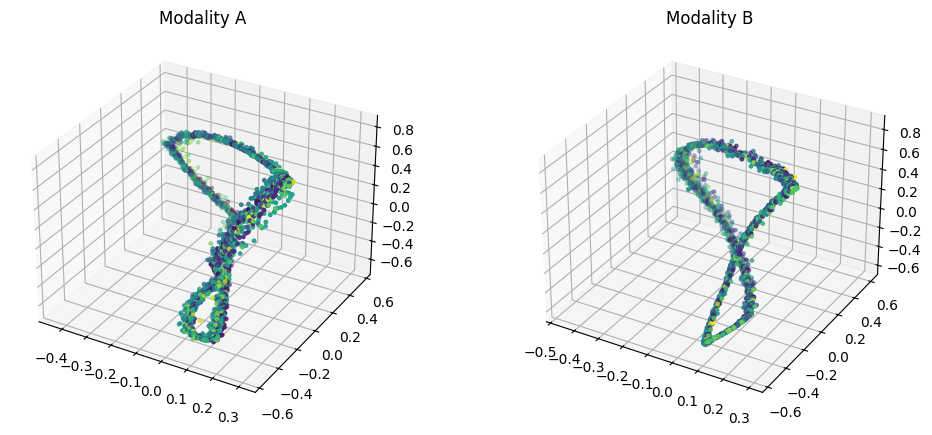

In [27]:
# 5) Visualize embeddings with our built-in viz
comets.plotemb2(
    ZA, ZB,
    color=position,               # color points by latent angle
    titles=("Modality A", "Modality B"),
    mode="direct"                  # project to 3D PCA for plotting
)

In [28]:
# 3) Baselines: PCA, UMAP (on each view separately)
# PCA and UMAP baselines
Z1_pca = PCA(n_components=3).fit_transform(A)
Z2_pca = PCA(n_components=3).fit_transform(B)


reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0)
Z1_umap = reducer.fit_transform(A)
Z2_umap = reducer.fit_transform(B)


f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [29]:
# Optional: CEBRA baseline
cebra_temp = 1
cebra_itr = 500
modelA_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=cebra_itr, output_dimension= 32,
                            batch_size=256, temperature=cebra_temp, verbose = True)
ZA_cebra = modelA_cebra.fit_transform(A)

modelB_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=cebra_itr, output_dimension = 16,
                            batch_size=256, temperature=cebra_temp
, verbose = True)
ZB_cebra = modelB_cebra.fit_transform(B)

pos: -0.9616 neg:  5.5872 total:  4.6256 temperature:  1.0000: 100%|██████████| 500/500 [00:04<00:00, 103.04it/s]
pos: -0.9721 neg:  5.6082 total:  4.6361 temperature:  1.0000: 100%|██████████| 500/500 [00:04<00:00, 116.22it/s]


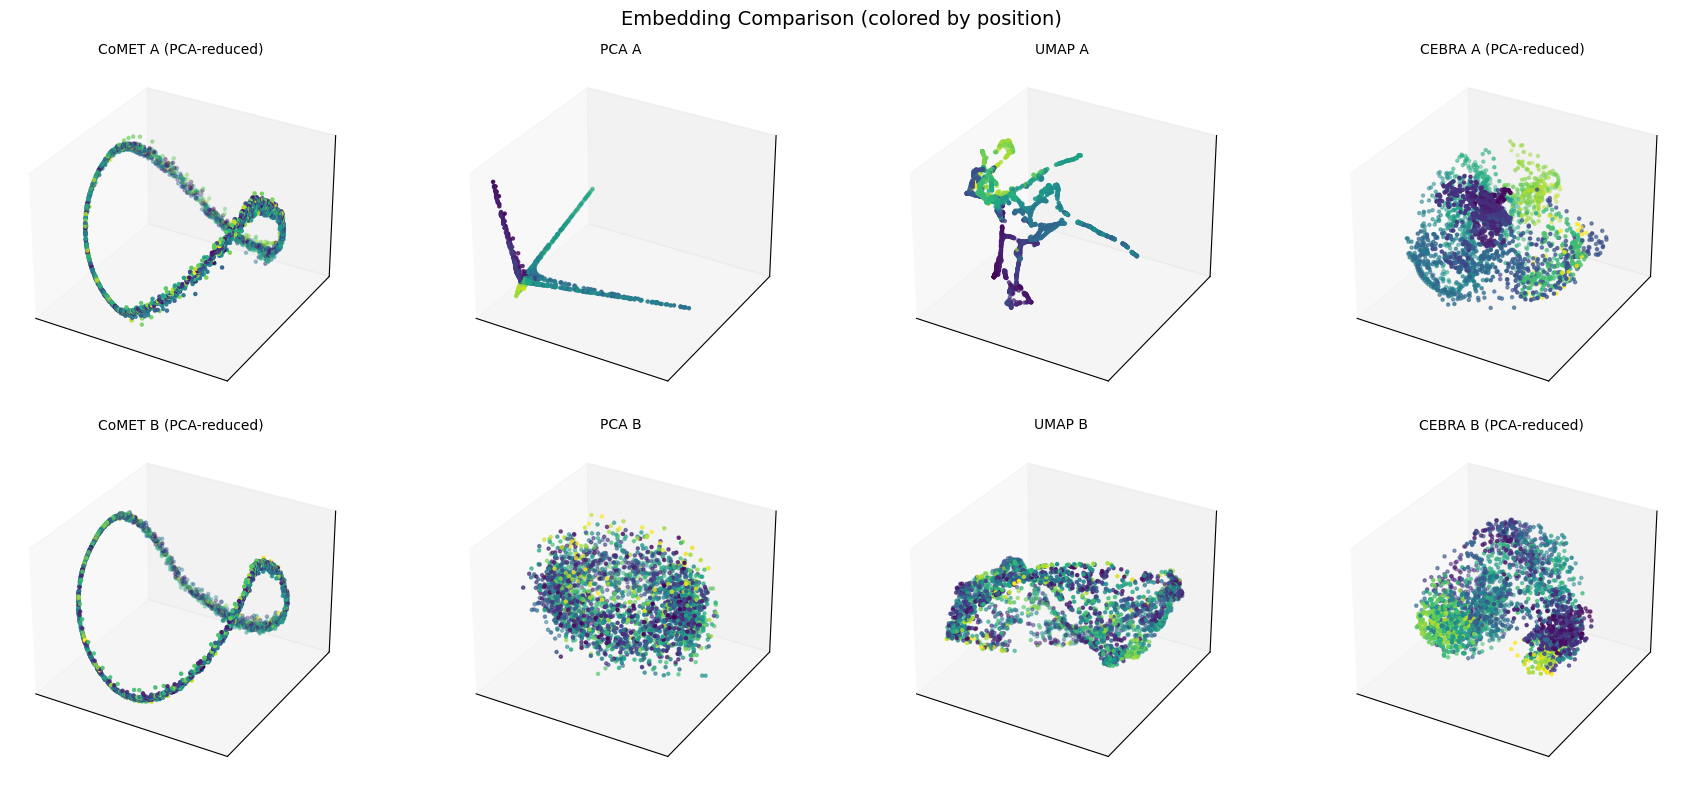

In [30]:

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=position, cmap='viridis', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=position, cmap='viridis', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by position)", fontsize=14)
plt.tight_layout()
plt.show()


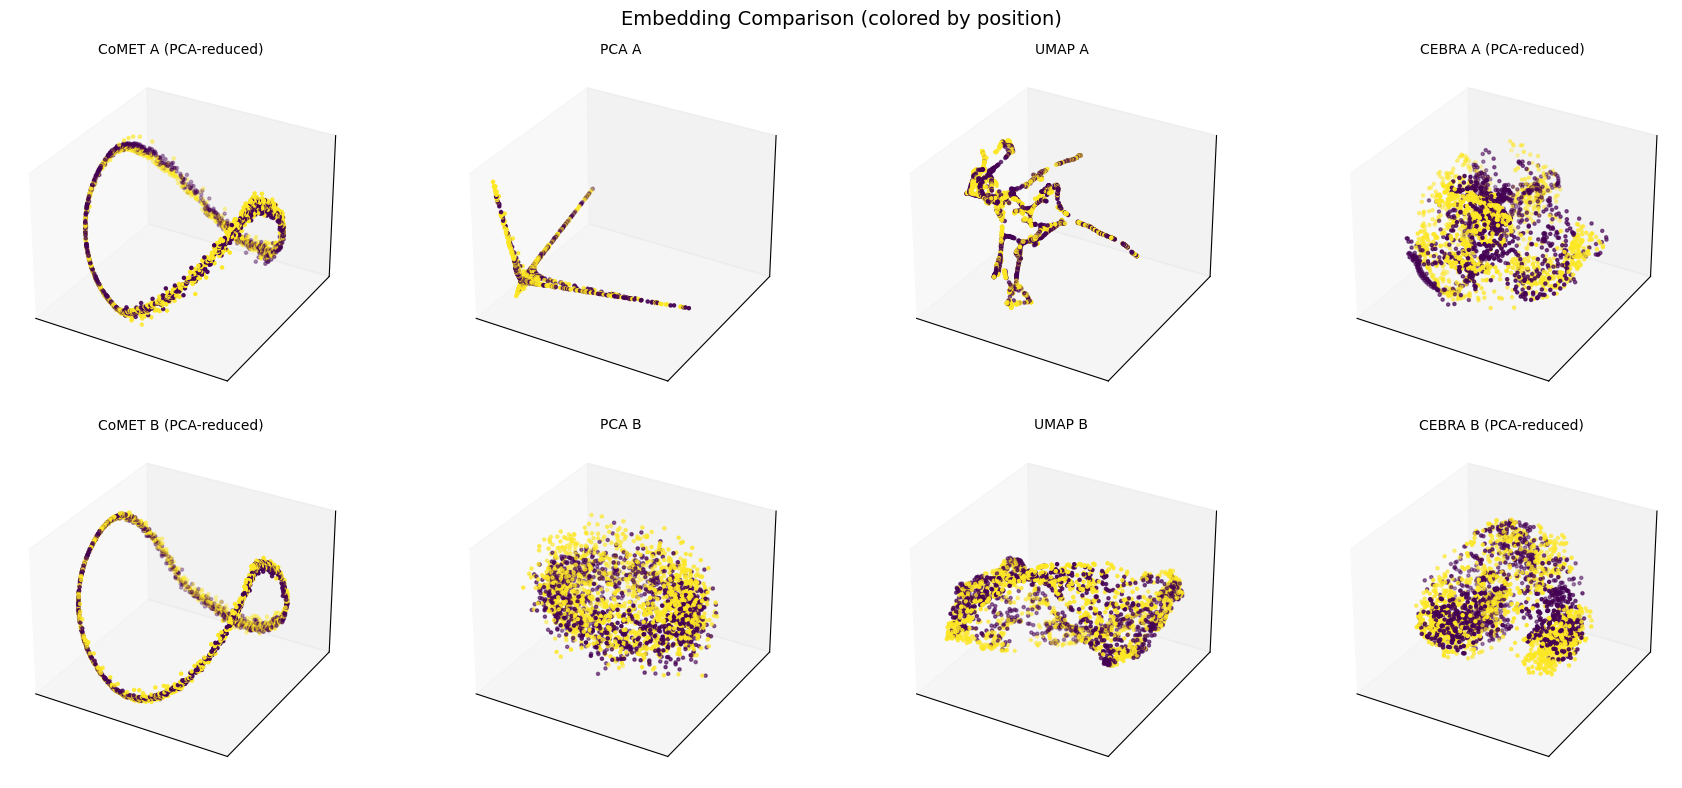

In [31]:

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=head_dir, cmap='viridis', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=head_dir, cmap='viridis', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by position)", fontsize=14)
plt.tight_layout()
plt.show()


In [32]:
# 6) Decoding: predict latent angles from embeddings
# We'll use Ridge regression to predict sin/cos of angle for circular decoding,
# then compute mean R^2 on sin and cos.

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [33]:

def linear_decode_score(Z, y):
    """Decode continuous variable y from embedding Z using ridge regression."""
    Z = np.asarray(Z)
    y = np.asarray(y).ravel()
    n = len(y)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha = 0.1)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    return r2_score(yte, yhat)

# -----------------------------
# Example decoding comparison
# -----------------------------
scores = {}
toval = position  # latent true position

scores['CoMETs_A'] = linear_decode_score(ZA, toval)
scores['CoMETs_B'] = linear_decode_score(ZB, toval)
scores['PCA_A']    = linear_decode_score(Z1_pca, toval)
scores['PCA_B']    = linear_decode_score(Z2_pca, toval)
scores['UMAP_A']   = linear_decode_score(Z1_umap, toval)
scores['UMAP_B']   = linear_decode_score(Z2_umap, toval)
scores['CEBRA_A']  = linear_decode_score(ZA_cebra, toval)
scores['CEBRA_B']  = linear_decode_score(ZB_cebra, toval)

print("Decoding scores (R² of position x):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")

Decoding scores (R² of position x):
CoMETs_A  : -0.062
CoMETs_B  : -0.103
PCA_A     : 0.061
PCA_B     : -0.058
UMAP_A    : 0.601
UMAP_B    : -0.091
CEBRA_A   : 0.678
CEBRA_B   : -1.329


In [34]:
# -----------------------------
# Example decoding comparison
# -----------------------------
scores = {}
toval = head_dir  # latent true position

scores['CoMETs_A'] = linear_decode_score(ZA, toval)
scores['CoMETs_B'] = linear_decode_score(ZB, toval)
scores['PCA_A']    = linear_decode_score(Z1_pca, toval)
scores['PCA_B']    = linear_decode_score(Z2_pca, toval)
scores['UMAP_A']   = linear_decode_score(Z1_umap, toval)
scores['UMAP_B']   = linear_decode_score(Z2_umap, toval)
scores['CEBRA_A']  = linear_decode_score(ZA_cebra, toval)
scores['CEBRA_B']  = linear_decode_score(ZB_cebra, toval)

print("Decoding scores (R² of position x):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")

Decoding scores (R² of position x):
CoMETs_A  : -0.073
CoMETs_B  : -0.081
PCA_A     : -0.074
PCA_B     : -0.020
UMAP_A    : -0.083
UMAP_B    : -0.088
CEBRA_A   : 0.225
CEBRA_B   : -1.006
